# étoiles Be avec compagne sd0 : [Le projet](https://gilgamir.github.io/be-binaries)

## chargement de la cible et correction barycentrique

In [40]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.modeling import models, fitting
from astropy.coordinates import SkyCoord, EarthLocation
from specutils import Spectrum, SpectralRegion
from astropy import units as u
from astropy.time import Time
from specutils.analysis import centroid, fwhm, equivalent_width, snr, snr_derived

# on charge le spectre
#filename = 'data/plouis/_otgem_20260321_861.fits'
#filename = 'data/plouis/_kxand_20251125_993.fits'
#filename = 'data/plouis/_60cyg_20261113_939_tell.fits'
#filename = 'data/plouis/_28cyg_20261113_852_tell.fits'
filename = 'data/plouis/_59cyg_20261113_899_tell.fits'

sp = Spectrum.read(filename)
#print(sp.meta)
# coordonnées de la capture - normalement dans l'entete FITS
# CALC : 
#LAT=48.12*u.deg
#LON=-1.63*u.deg
#ELEV=10*u.m

print(sp.meta['header']['OBJECT'])
LON=sp.meta['header']['GEO_LONG']*u.deg
LAT=-sp.meta['header']['GEO_LAT']*u.deg
ELEV=sp.meta['header']['GEO_ELEV']*u.m

print(f"Location obs: long={LON}, lat={LAT}, elev={ELEV}")

# Correction de la vitesse barycentrique de la Terre 
c = 299792458  # m/s 
location = EarthLocation(lat=LAT, lon=LON, height=ELEV)   
target = SkyCoord.from_name(sp.meta['header']['OBJECT'])
t = Time(float(sp.meta['header']['JD-OBS']), format='jd', scale='utc')
v_bary = target.radial_velocity_correction(kind='barycentric', obstime=t, location=location)
beta = v_bary / c * u.Unit('m/s')
doppler_factor = np.sqrt((1 + beta.value) / (1 - beta.value))  
lambda_corrected = sp.spectral_axis * doppler_factor
spec_corrected = Spectrum(spectral_axis=lambda_corrected, flux=sp.flux)

print(f"{v_bary=}, {doppler_factor=}")    
print(f"Décalage moyen : {np.mean((lambda_corrected - sp.spectral_axis).value):.6f} Å")

# Extraction des valeurs brutes (pour éviter les soucis avec les unités astropy)
x_data = spec_corrected.spectral_axis.value
y_data = spec_corrected.flux.value 


59Cyg
Location obs: long=-1.63 deg, lat=-48.12 deg, elev=55.0 m
v_bary=<Quantity -14174.19130573 m / s>, doppler_factor=np.float64(0.9999527211046664)
Décalage moyen : -0.312058 Å


## ajustement H alpha

------------------------------------------------------------
Résolution (Néon)           : 0.412 A    | rms ajustement : 0.0201
Largeur commune V/R (sigma) : 2.05 A | piédestal FWHM : 11.0 A
Pics du profil   : NON résolus dans le profil ajusté (épaulement) -> utiliser les composantes
Composantes      V = 6560.391 +/- 0.072   R = 6565.076 +/- 0.037 A
   séparation : 4.686 A -> vitesse 107.0 km/s
   V/R (amplitudes gaussiennes) : 1.433
------------------------------------------------------------


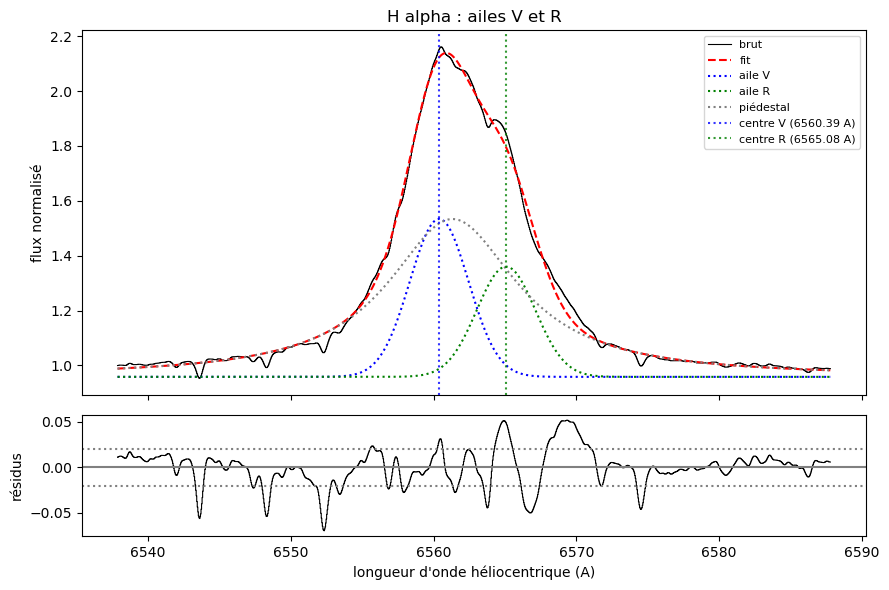

In [41]:
# ATTENTION : le spectre autour de H alpha d'une étoile Be est un 'shell', i.e. une enveloppe de gaz autour de l'étoile
# -> le modèle à ajuster n'est PAS une double gaussienne mais une large gaussienne en émission, 'percée' d'une étroite gaussienne en absorption

# est-ce que la Be possède un creux central en abs sur H alpha ?
use_central_abs = False 

import numpy as np
import matplotlib.pyplot as plt
from astropy.modeling import models, fitting
from scipy.signal import find_peaks
import astropy.units as u

c = 299792.458      # km/s
fwhm_neon_pix = 5.45   # largeur raie néon en px, retourné par specinti
disp_physique = 0.0756 # A/pixel dispersion du starEx2400, retourné par specinti

lambda_ha = 6562.82
window_width = 25      # nb angstroms de chaque côté
v_lim = 450.           # km/s : domaine autorisé pour les centres V et R (de part et d'autre de lambda_ha)

## Découpage de la zone
mask = (x_data > lambda_ha - window_width) & (x_data < lambda_ha + window_width)
x_win = x_data[mask]
y_win = y_data[mask]

# ---------------------------------------------------------------------------
# Modèle utilisé : 
#  - continuum + aile bleue (V) + aile rouge (R) + piédestal large [+ creux central]
#  - V et R : 2 gaussiennes de même largeur, centres bornés de chaque côté de lambda_ha
#  - piédestal lorentzien : ailes larges communes (diffusion électronique) -> évite que V et R ne servent à décrire les ailes, ce qui faisait diverger l'ajustement à 2 gaussiennes
# ---------------------------------------------------------------------------
dl = lambda_ha * v_lim / c
cont = models.Const1D(amplitude=1.0, bounds={'amplitude': (0.9, 1.1)}, name='cont')
g_V  = models.Gaussian1D(amplitude=0.5, mean=lambda_ha - 1.5, stddev=1.5,
                         bounds={'amplitude': (0, 3), 'mean': (lambda_ha - dl, lambda_ha), 'stddev': (0.5, 5)}, name='V')
g_R  = models.Gaussian1D(amplitude=0.5, mean=lambda_ha + 1.5, stddev=1.5,
                         bounds={'amplitude': (0, 3), 'mean': (lambda_ha, lambda_ha + dl), 'stddev': (0.5, 5)}, name='R')
g_R.stddev.tied = lambda m: m['V'].stddev                   # même largeur pour V et R
ped  = models.Lorentz1D(amplitude=0.5, x_0=lambda_ha, fwhm=6,
                         bounds={'amplitude': (0, 3), 'x_0': (lambda_ha - 1.5, lambda_ha + 1.5), 'fwhm': (2, 30)}, name='ped')
model_init = cont + g_V + g_R + ped
if use_central_abs:
    absn = models.Gaussian1D(amplitude=-0.1, mean=lambda_ha, stddev=0.8,
                             bounds={'amplitude': (-1, 0), 'mean': (lambda_ha - 1.5, lambda_ha + 1.5), 'stddev': (0.2, 2)}, name='abs')
    model_init = model_init + absn

fitter = fitting.LevMarLSQFitter(calc_uncertainties=True)
fit_result = fitter(model_init, x_win, y_win, maxiter=2000)

# courbe fittée sur une grille fine (0.01 A) pour trouver les maxima avec précision
x_fine = np.arange(x_win.min(), x_win.max(), 0.01)
y_fit = fit_result(x_fine)
y_fit_win = fit_result(x_win)
rms = np.std(y_win - y_fit_win)

# ---------------------------------------------------------------------------
# 1) pics du PROFIL ajusté : maxima locaux de part et d'autre de la vallée centrale
# ---------------------------------------------------------------------------
sel = (x_fine > lambda_ha - dl) & (x_fine < lambda_ha + dl)
pk, _ = find_peaks(y_fit[sel])
resolved = len(pk) >= 2
if resolved:
    pk = pk[np.argsort(y_fit[sel][pk])[-2:]]              # les 2 maxima les plus hauts
    pk = np.sort(pk)
    x_V, x_R = x_fine[sel][pk[0]], x_fine[sel][pk[1]]
    V_amplitude, R_amplitude = y_fit[sel][pk[0]], y_fit[sel][pk[1]]
else:
    x_V = x_R = V_amplitude = R_amplitude = np.nan

# ---------------------------------------------------------------------------
# 2) centres des composantes V et R 
# ---------------------------------------------------------------------------
cV, cR = fit_result['V'].mean.value, fit_result['R'].mean.value
try:
    ecV, ecR = fit_result['V'].mean.std, fit_result['R'].mean.std
except Exception:
    ecV = ecR = np.nan

if ecV == None: ecV = np.nan
if ecR == None: ecR = np.nan

# incertitude instrumentale (néon) sur la position d'un pic : 1/10 de la FWHM
fwhm_inst_a = fwhm_neon_pix * disp_physique
err_pos = fwhm_inst_a / 10.0
err_delta_lambda = np.sqrt(2) * err_pos

def v_disk(dL):  return c * dL / lambda_ha / 2

print("-" * 60)
print(f"Résolution (Néon)           : {fwhm_inst_a:.3f} A    | rms ajustement : {rms:.4f}")
print(f"Largeur commune V/R (sigma) : {fit_result['V'].stddev.value:.2f} A | piédestal FWHM : {fit_result['ped'].fwhm.value:.1f} A")
if resolved:
    dL = x_R - x_V
    print(f"Pics du profil   V = {x_V:.3f}   R = {x_R:.3f} A   (+/- {err_pos:.3f})")
    print(f"   séparation : {dL:.3f} +/- {err_delta_lambda:.3f} A -> vitesse bord du disque {v_disk(dL):.1f} +/- {c*err_delta_lambda/(2*lambda_ha):.1f} km/s")
    print(f"   V/R (flux aux pics) : {V_amplitude / R_amplitude:.3f}")
else:
    print("Pics du profil   : NON résolus dans le profil ajusté (épaulement) -> utiliser les composantes")
dLc = cR - cV
print(f"Composantes      V = {cV:.3f} +/- {ecV:.3f}   R = {cR:.3f} +/- {ecR:.3f} A")
print(f"   séparation : {dLc:.3f} A -> vitesse {v_disk(dLc):.1f} km/s")
print(f"   V/R (amplitudes gaussiennes) : {fit_result['V'].amplitude.value / fit_result['R'].amplitude.value:.3f}")
print("-" * 60)

# ---------------------------------------------------------------------------
# affichage matplotlib (spectre + composantes, puis résidus)
# ---------------------------------------------------------------------------
c0 = fit_result['cont'].amplitude.value
fig, ax = plt.subplots(2, 1, figsize=(9, 6), sharex=True, gridspec_kw=dict(height_ratios=[3, 1]))
ax[0].plot(x_win, y_win, 'k', lw=0.8, drawstyle='steps-mid', label='brut')
ax[0].plot(x_fine, y_fit, 'r--', label='fit')
ax[0].plot(x_fine, c0 + fit_result['V'](x_fine), 'b:', label='aile V')
ax[0].plot(x_fine, c0 + fit_result['R'](x_fine), 'g:', label='aile R')
ax[0].plot(x_fine, c0 + fit_result['ped'](x_fine), color='gray', ls=':', label='piédestal')
if use_central_abs:
    ax[0].plot(x_fine, c0 + fit_result['abs'](x_fine), color='purple', ls=':', label='creux central')
if resolved:
    ax[0].axvline(x_V, color='blue', alpha=0.8, label=f'pic V ({x_V:.2f} A)')
    ax[0].axvline(x_R, color='green', alpha=0.8, label=f'pic R ({x_R:.2f} A)')
ax[0].axvline(cV, color='blue', ls=':', alpha=0.8, label=f'centre V ({cV:.2f} A)')
ax[0].axvline(cR, color='green', ls=':', alpha=0.8, label=f'centre R ({cR:.2f} A)')
ax[0].set_ylabel('flux normalisé')
ax[0].set_title('H alpha : ailes V et R')
ax[0].legend(fontsize=8, loc='upper right')

ax[1].plot(x_win, y_win - y_fit_win, 'k', lw=0.8, drawstyle='steps-mid')
ax[1].axhline(0, color='gray')
ax[1].axhline(rms, color='gray', ls=':'); ax[1].axhline(-rms, color='gray', ls=':')
ax[1].set_ylabel('résidus')
ax[1].set_xlabel("longueur d'onde héliocentrique (A)")
plt.tight_layout()
plt.show()

## ajustement HeI

In [48]:
# ============================================================
# He I 6678 : absorption photosphérique (profil de rotation) + émission étroite du disque chauffé
# Issu de Peters et al. 2013 (arXiv:1301.0257, §4) : l'émission He I 6678 formée dans la zone
# du disque éclairée par le compagnon sdO suit une courbe de vitesse radiale de même forme que
# celle du sdO, mais avec une plus grande amplitude (K_em ~ 180 km/s pour 59 Cyg)
# ============================================================
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import least_squares

C_KMS      = 299792.458
LAM_HEI    = 6678.1517          # He I 6678 (air)
R_POWER    = 16000              # SPE_RPOW dans l'entête (≈16040 pour ces trois spectres)

# ---------- 1. éléments orbitaux de 59 Cyg (Peters+2013, Table 2, colonne "IUE ccfs") - à rédéfinir avant appel à fit_hei()  ----------
ORB_59CYG = dict(P=28.1871, T0=2445677.6, e=0.141, w1_deg=257., K2=121.3, g2=-10.4, K1=11.7, g1=2.1, Kem=180.)

def orbital_prediction(jd, orb=ORB_59CYG):
    """phase (0 = périastre), V_sdO et V_émission HeI attendue (km/s, héliocentrique)"""
    P, T0, e = orb['P'], orb['T0'], orb['e']
    w2 = np.radians(orb['w1_deg'] + 180.)
    M = 2*np.pi*(((jd - T0)/P) % 1.0)
    E = M
    for _ in range(50):                                   # équation de Kepler
        E -= (E - e*np.sin(E) - M)/(1 - e*np.cos(E))
    nu = 2*np.arctan2(np.sqrt(1+e)*np.sin(E/2), np.sqrt(1-e)*np.cos(E/2))
    v2 = orb['g2'] + orb['K2']*(np.cos(nu + w2) + e*np.cos(w2))
    # l'émission a la même forme mais une amplitude K_em/K2 fois plus grande (hypothèse simple)
    v_em = orb['g1'] + (orb['Kem']/orb['K2'])*(v2 - orb['g2'])
    return M/(2*np.pi), v2, v_em

# ---------- 2. profils ----------
def rot_profile(dlam, lam0, vsini, eps=0.4):
    """profil de rotation de Gray (assombrissement centre-bord eps), normalisé à une aire de 1"""
    dL = lam0*vsini/C_KMS
    u = np.clip(1 - (dlam/dL)**2, 0, None)
    prof = (2*(1-eps)*np.sqrt(u) + 0.5*np.pi*eps*u) / (np.pi*dL*(1 - eps/3))
    return prof

def model_hei(p, x, fwhm_inst):
    """p = [cont, A_abs, lam_abs, vsini, A_em, lam_em, sig_em]  (A_abs = aire de l'absorption en Å, >0)"""
    cont, A_abs, lam_abs, vsini, A_em, lam_em, sig_em = p
    
    # grille fine pour convoluer l'absorption par la fonction d'appareil
    xf = np.arange(x.min()-10, x.max()+10, 0.01)
    absf = A_abs*rot_profile(xf - lam_abs, LAM_HEI, vsini)
    sig_i = fwhm_inst/2.355/0.01
    k = np.arange(-int(5*sig_i), int(5*sig_i)+1)
    kern = np.exp(-0.5*(k/sig_i)**2); kern /= kern.sum()
    absf = np.convolve(absf, kern, mode='same')
    absorption = np.interp(x, xf, absf)
    
    # l'émission est aussi élargie par l'instrument
    sig_tot = np.hypot(sig_em, fwhm_inst/2.355)
    emission = A_em/(np.sqrt(2*np.pi)*sig_tot)*np.exp(-0.5*((x-lam_em)/sig_tot)**2)
    return cont - absorption + emission

def fit_hei(x, y, jd=None, label='', orb=ORB_59CYG, plot=True, v_search=300., win=(6645., 6715.),
            cont_windows=((6645., 6657.), (6700., 6730.)), vsini_guess=350., vsini_fixed=None):
    fwhm_inst = LAM_HEI/R_POWER
    # --- continuum local : droite ajustée (avec clipping) sur des fenêtres sans raie
    mc = np.zeros_like(x, bool)
    for a, b in cont_windows: mc |= (x > a) & (x < b)
    good = mc.copy()
    for _ in range(5):
        co = np.polyfit(x[good]-LAM_HEI, y[good], 1)
        res = y[mc] - np.polyval(co, x[mc]-LAM_HEI)
        s = 1.4826*np.median(np.abs(res - np.median(res)))
        good = mc & (np.abs(y - np.polyval(co, x-LAM_HEI)) < 3*s)
    yn = y/np.polyval(co, x-LAM_HEI)
    noise = 1.4826*np.median(np.abs(yn[mc]-np.median(yn[mc])))     # bruit par pixel ; S/N ~ 1/noise
    m = (x > win[0]) & (x < win[1])
    xw, yw = x[m], yn[m]

    # --- ajustement : on compare 'absorption seule' et 'absorption + émission'
    dlam_s = LAM_HEI*v_search/C_KMS
    # cont  A_abs  lam_abs  vsini  A_em  lam_em   sig_em
    lo = np.array([0.9,  0.0, LAM_HEI-1.5, 100., 0.0, LAM_HEI-dlam_s, 0.15])
    hi = np.array([1.1,  20., LAM_HEI+1.5, 500., 3.0, LAM_HEI+dlam_s, 1.5])
    if vsini_fixed is not None:            # ex. 379 km/s pour 59 Cyg (Fremat+05) : évite que l'émission fausse la largeur
        lo[3], hi[3], vsini_guess = vsini_fixed-1., vsini_fixed+1., vsini_fixed
    p0 = np.array([1.0,  3.0, LAM_HEI,     vsini_guess, 0.05, LAM_HEI-2., 0.5])
    
    def resid_full(p): return (model_hei(p, xw, fwhm_inst) - yw)/noise
    
    # absorption seule : A_em = 0 figé
    def resid_abs(q): return resid_full(np.r_[q, 0., LAM_HEI, 0.5])
        
    f0 = least_squares(resid_abs, p0[:4], bounds=(lo[:4], hi[:4]))
    
    # on essaie plusieurs positions de départ pour l'émission (minima locaux)
    best = None
    for lam_start in np.linspace(LAM_HEI-dlam_s*0.9, LAM_HEI+dlam_s*0.9, 9):
        p_init = np.r_[f0.x, 0.05, lam_start, 0.5]
        try:
            f = least_squares(resid_full, p_init, bounds=(lo, hi))
        except Exception:
            continue
        if best is None or f.cost < best.cost: best = f
    f1 = best
    n = len(xw)
    bic0 = 2*f0.cost + 4*np.log(n)
    bic1 = 2*f1.cost + 7*np.log(n)
    
    # --- incertitudes (matrice de covariance) ; bruit déjà inclus dans les résidus pondérés
    J = f1.jac
    try:
        cov = np.linalg.inv(J.T @ J) * (2*f1.cost/(n-7))
        err = np.sqrt(np.diag(cov))
    except np.linalg.LinAlgError:
        err = np.full(7, np.nan)
    cont, A_abs, lam_abs, vsini, A_em, lam_em, sig_em = f1.x

    # --- vitesse héliocentrique de l'émission (x est supposé déjà corrigé de la vitesse barycentrique)
    v_em  = C_KMS*(lam_em - LAM_HEI)/LAM_HEI
    ev_em = C_KMS*err[5]/LAM_HEI
    v_abs = C_KMS*(lam_abs - LAM_HEI)/LAM_HEI
    ew_em = A_em/cont            # Å (>0 = émission)
    ew_ab = A_abs/cont
    fwhm_em_kms = C_KMS*2.355*np.hypot(sig_em, fwhm_inst/2.355)/LAM_HEI
    snr_em = A_em/err[4] if err[4] > 0 else np.nan

    out = dict(label=label, v_em=v_em, ev_em=ev_em, v_abs=v_abs, vsini=vsini, evsini=err[3],
               ew_em=ew_em, ew_abs=ew_ab, snr_em=snr_em, dBIC=bic0-bic1, noise=noise,
               fwhm_em=fwhm_em_kms, params=f1.x, jd=jd)

    print('-'*62)
    print(f"{label}   (bruit continuum = {noise:.4f} -> S/N ~ {1/noise:.0f} /pixel)")
    print(f"Absorption : EW = {ew_ab:.2f} A | v sin i = {vsini:.0f} +/- {err[3]:.0f} km/s | décalage = {v_abs:+.0f} km/s")
    print(f"Émission   : EW = {ew_em*1000:.0f} mA | V = {v_em:+.1f} +/- {ev_em:.1f} km/s | FWHM = {fwhm_em_kms:.0f} km/s")
    print(f"Signif.    : A_em/sigma = {snr_em:.1f} | dBIC (abs seule - abs+em) = {bic0-bic1:.0f}  (>10 : l'émission est requise)")
    if jd is not None:
        ph, v2, vem_pred = orbital_prediction(jd, orb)
        print(f"Prédiction {sp.meta['header']['OBJECT']} : phase = {ph:.3f} | V(sdO) = {v2:+.0f} km/s | V(émission HeI) ~ {vem_pred:+.0f} km/s")
    print('-'*62)

    if plot:
        fig, ax = plt.subplots(2, 1, figsize=(9, 6), sharex=True, gridspec_kw=dict(height_ratios=[3, 1]))
        xf = np.linspace(xw.min(), xw.max(), 2000)
        ax[0].plot(xw, yw, 'k', lw=0.8, drawstyle='steps-mid', label='spectre normalisé')
        ax[0].plot(xf, model_hei(f1.x, xf, fwhm_inst), 'r', label='absorption + émission')
        pabs = f1.x.copy(); pabs[4] = 0.
        ax[0].plot(xf, model_hei(pabs, xf, fwhm_inst), 'b--', label='absorption seule')
        ax[0].axvline(LAM_HEI, color='gray', ls=':'); ax[0].axvline(lam_em, color='r', ls=':')
        ax[0].set_ylabel('flux normalisé'); ax[0].legend(loc='lower left'); ax[0].set_title(label)
        ax[1].plot(xw, yw - model_hei(pabs, xw, fwhm_inst), 'k', lw=0.8, drawstyle='steps-mid')
        ax[1].plot(xw, yw - model_hei(f1.x, xw, fwhm_inst), 'r', lw=0.8, drawstyle='steps-mid')
        ax[1].axhline(0, color='gray'); ax[1].axhline(3*noise, color='gray', ls=':'); ax[1].axhline(-3*noise, color='gray', ls=':')
        ax[1].set_ylabel('résidus'); ax[1].set_xlabel('longueur d\'onde héliocentrique (A)')
        plt.tight_layout(); plt.show()
        
    return out
    

--------------------------------------------------------------
59Cyg   (bruit continuum = 0.0027 -> S/N ~ 371 /pixel)
Absorption : EW = 0.16 A | v sin i = 380 +/- 8 km/s | décalage = -67 km/s
Émission   : EW = 165 mA | V = -140.1 +/- 0.8 km/s | FWHM = 103 km/s
Signif.    : A_em/sigma = 45.5 | dBIC (abs seule - abs+em) = 20070  (>10 : l'émission est requise)
Prédiction 59Cyg : phase = 0.311 | V(sdO) = -118 km/s | V(émission HeI) ~ -158 km/s
--------------------------------------------------------------


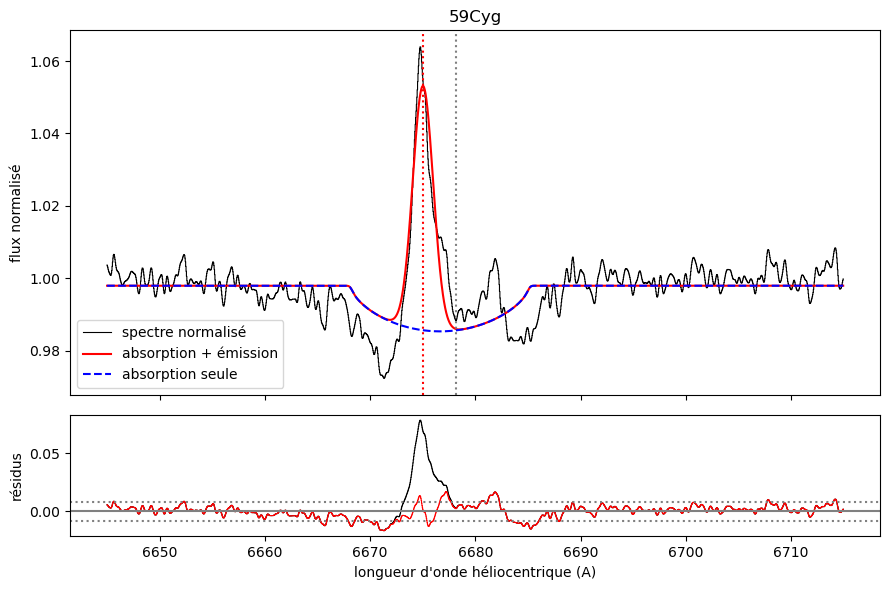

In [49]:
ORB_59CYG = dict(P=28.1871, T0=2445677.6, e=0.141, w1_deg=257., K2=121.3, g2=-10.4, K1=11.7, g1=2.1, Kem=180.)

#def fit_hei(x, y, jd=None, label='', plot=True, v_search=300., win=(6645., 6715.), cont_windows=((6645., 6657.), (6700., 6730.)), vsini_guess=350., vsini_fixed=None):

res = fit_hei(x_data, y_data, 
              orb=ORB_59CYG, 
              jd=float(sp.meta['header']['JD-OBS']), 
              label=sp.meta['header']['OBJECT'], 
              vsini_fixed=379)

#Pour 28 Cyg et 60 Cyg, vsini_fixed=None et le v sin i sera ajusté (j’obtiens 310 et 375 km/s).




## Résultats du 13 novembre 2026 :

| Étoile| 	Émission HeI| 	Verdict| 
| ------ | ----------- |----------- |
| 59 Cyg| 	V ≈ −140 km/s, EW ≈ 165 mÅ, FWHM ≈ 104 km/s, | significatif : Phase 0,311, émission attendue vers −158 km/s : accord à ~18 km/s| 
| 28 Cyg| 	Excès large (FWHM ≈ 160 km/s) à environ +220 km/s	| Compatible avec une émission déplacée, mais aussi avec une asymétrie du profil. Un seul spectre ne tranche pas| 
| 60 Cyg| 	~7 mÅ, environ 4σ, ΔBIC = 18	| Marginal, pas d'interprétation| 


- 59 Cyg : l’émission varie peu quand on change le traitement de l’absorption (−139,9 ou −139,7 km/s). L’écart de 18 km/s avec la prédiction reste dans l’incertitude, car l’éphéméride est extrapolée sur environ 556 cycles et la loi K_em/K₂ est une hypothèse simple.
- Absorption de 59 Cyg : elle est comblée par l’émission, donc moins fiable que celles de 28 Cyg et 60 Cyg.
- Correction barycentrique : pour les tests j’ai appliqué environ −13,8 km/s aux trois spectres (coordonnées approchées).
- Un seul spectre place un point sur la courbe de vitesse, il ne prouve pas l’orbite. Pour 59 Cyg, quelques spectres répartis sur les 28,19 jours de la période, passés dans fit_kem, donneraient K_em.
- Pour 28 Cyg et 60 Cyg, il faudrait suivre l’émission HeI dans le temps : si elle se déplace avec une période stable, ce serait un indice.
- Enfin, un spectre sur He II 4686 serait la détection directe de l’sdO.


## Comparaison avec Peters et al. 2013 (59 Cyg).

Ce que dit la publi

- Le compagnon sdO est détecté directement dans l’UV (IUE), et en optique par He II 4686 en antiphase (Maintz et al.).
- La preuve accessible ici est l’émission étroite de He I 6678, formée dans la partie du disque éclairée par l’sdO. Sa vitesse suit celle de l’sdO avec une amplitude plus grande (K_em = 180 ± 10 km/s contre K₂ = 121 km/s). Éléments orbitaux utilisés : P = 28,1871 j, e = 0,141, K₂ = 121,3 km/s.

Ce que donnent les spectres du 13 / 11

- la phase orbitale de 59 Cyg est 0,311. Les éléments de la publi prédisent alors une vitesse de l’sdO d’environ −118 km/s, soit une émission He I vers −158 km/s.
- On mesure une émission étroite à environ −140 km/s (FWHM ≈ 104 km/s, EW ≈ 165 mÅ), très significative. L’écart avec la prédiction est d’environ 18 km/s.
- Cet écart reste raisonnable. L’éphéméride est extrapolée sur environ 556 cycles, ce qui représente quelques centièmes de phase, soit une dizaine de km/s à cette phase. De plus, l’amplitude de l’émission est déduite de celle de l’sdO par une simple proportion K_em/K₂.

Ce que ça prouve, et ce que ça ne prouve pas

- Pour 59 Cyg, l’émission est présente, décalée vers le bleu comme attendu à cette phase, et compatible avec l’orbite publiée. C’est cohérent avec la présence du compagnon.
- Un seul point ne démontre pas l’orbite. Pour confirmer K_em, il faudrait plusieurs spectres répartis sur les 28 jours de la période, à passer dans fit_kem.


En conclusion 

- L’émission : un point chaud, pas un anneau
- Mesuré sur le spectre normalisé, le pic est vers −140/−150 km/s (FWHM ≈ 100 km/s, la résolution instrumentale ne représente que ≈ 19 km/s). La logique de l’article (éq. 1) est la suivante :

- Le gaz du disque proche de l’sdO est éclairé et chauffé, et c’est lui qui émet en He I 6678.
- Ce gaz orbite autour de la Be en orbite képlérienne. Plus proche de la Be que l’sdO, il va plus vite que lui : (K₁+K_em)/(K₁+K₂) = √[M₁/(M₁+M₂) · a/R]. Avec K₁=11,7, K₂=121,3 et K_em=180 km/s, on obtient R_em/a ≈ 0,44.
- Avec a·sin i = 73 R☉, cela donne R_em ≈ 33–37 R☉, soit environ 5 rayons de la Be, à peu près à mi-chemin entre les deux étoiles. C’est probablement près du bord externe du disque.
- Si le disque entier émettait, un anneau donnerait un double pic de part et d’autre de la vitesse de la Be. Ici le pic est unique et suit l’orbite : l’émission est localisée sur la face tournée vers l’sdO. À la phase 0,31, l’sdO s’approche (≈ −118 km/s), donc l’émission est décalée vers le bleu, comme l’orbite le prédit.
- La largeur de ~100 km/s vient sans doute de l’étendue en rayon et en azimut de la zone éclairée, mais c’est une interprétation de ma part.


Le creux d’absorption autour du pic

C’est la raie He I photosphérique de la Be (v sin i ≈ 380 km/s, creux large de ±8,5 Å). Mes mesures sur le spectre lissé :

| Étoile| 	Émission HeI| 	Verdict| 

| Zone	| Position	| Profondeur| 
| ------ | ----------- |----------- |
| Creux | côté bleu	≈ −307 km/s	| ≈ 2,7 %| 
| Creux | côté rouge	≈ +37 km/s| 	≈ 1,1 %| 

Cette asymétrie n’est pas entièrement expliquée, et le modèle ne la reproduit pas : ses résidus montrent un déficit vers 6672 Å.

- Remplissage par l’émission : l’article note (§2) que l’émission He I comble l’absorption et fausse les vitesses apparentes. L' ajustement trouve d’ailleurs un creux décalé d’environ −67 km/s, bien plus que K₁ ≈ 12 km/s. Mais le pic est à −150 km/s, donc ce remplissage n’explique pas à lui seul le creux rouge peu profond à +37 km/s.
- Profondeur du creux bleu : à −307 km/s, il est plus profond que ce qu’un creux rotationnel d’EW ≈ 0,2 Å donnerait (≈ 1 à 1,5 %). Il faudrait donc une absorption supplémentaire côté bleu. Je n’ai pas d’explication établie : gaz du disque ou de l’enveloppe devant l’étoile (l’article donne i ≈ 60–80°), ou résidu de correction tellurique.
Artefact instrumental ? C’est peu probable : 28 Cyg et 60 Cyg, observées la même nuit avec le même instrument, ont des creux symétriques et bien ajustés.

- Deux vérifications possibles : comparer avec le spectre avant correction tellurique, et voir sur d’autres dates si le creux bleu bouge avec l’émission ou reste fixe. Dans le premier cas il serait lié au gaz éclairé, dans le second à l’étoile ou à l’enveloppe.



## calcul de l'orbite de la sdO (nécéssite plusieurs spectres)

In [51]:
# ---------- 3. avec plusieurs dates : K_em de l'émission He I ----------
def fit_kem(jds, v_em, ev_em=None, orb=ORB_59CYG):
    """ajuste V_em(t) = gamma + s*(V_sdO(t)-gamma2) avec la phase orbitale de Peters+13 ; K_em = s*K2.
    Il faut des observations réparties sur toute la période de 28,19 j (et quelques spectres par phase)."""
    jds, v_em = np.asarray(jds, float), np.asarray(v_em, float)
    f = np.array([orbital_prediction(j, orb)[1] - orb['g2'] for j in jds])
    w = 1/np.asarray(ev_em, float) if ev_em is not None else np.ones_like(v_em)
    A = np.vstack([np.ones_like(f), f]).T * w[:, None]
    (g, sl), *_ = np.linalg.lstsq(A, v_em*w, rcond=None)
    rms = np.std(v_em - (g + sl*f))
    print(f"gamma_em = {g:+.1f} km/s | K_em = {sl*orb['K2']:.0f} km/s (Peters+13 : 180 +/- 10) | rms = {rms:.1f} km/s")
    return g, sl*orb['K2']

In [55]:
#out = dict(label=label, v_em=v_em, ev_em=ev_em, v_abs=v_abs, vsini=vsini, evsini=err[3],
#               ew_em=ew_em, ew_abs=ew_ab, snr_em=snr_em, dBIC=bic0-bic1, noise=noise,
#               fwhm_em=fwhm_em_kms, params=f1.x, jd=jd)

orb = fit_kem(jds=float(sp.meta['header']['JD-OBS']),
             v_em=res['v_em'],
             ev_em=res['ev_em'],
             orb=ORB_59CYG)



TypeError: iteration over a 0-d array